# 03 — Pooled TCN / 1D-CNN Comparison

Compare TCN and 1D-CNN forecasts against the saved pooled LSTM and persistence baseline. Data preparation and split-local windowing are copied from `02_LSTM.ipynb`; no wind-direction features are included. Models train jointly on all stations, use train-only station scalers, and report test metrics in original concentration units.

## 1. Configuration

In [2]:

from pathlib import Path

LOOKBACK = 48
HORIZONS = [1, 6, 24]
BATCH_SIZE = 256
EPOCHS = 50
LR = 1e-3
HIDDEN = 64
LAYERS = 2
DROPOUT = 0.2
RANDOM_SEED = 42
EARLY_STOPPING_PATIENCE = 8
SCHEDULER_PATIENCE = 3

DATA_PATH = Path(r"C:\Users\jains\Downloads\Air quality dataset\cleaned\air_quality_all_stations_cleaned.csv")
RESULTS_DIR = Path.cwd() / "tcn_cnn_results"
LSTM_RESULTS_DIR = Path.cwd() / "lstm_results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
print(f"Data: {DATA_PATH}")
print(f"Results: {RESULTS_DIR.resolve()}")
print(f"Saved LSTM results: {LSTM_RESULTS_DIR.resolve()}")


Data: C:\Users\jains\Downloads\Air quality dataset\cleaned\air_quality_all_stations_cleaned.csv
Results: E:\coding\DL2project\tcn_cnn_results
Saved LSTM results: E:\coding\DL2project\lstm_results


## 2. Imports, reproducibility, and device

In [3]:

import copy
import random
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import Dataset, DataLoader
from IPython.display import display, Markdown
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def set_seed(seed=RANDOM_SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

set_seed()
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if DEVICE.type == "cpu":
    torch.set_num_threads(min(8, torch.get_num_threads()))
print(f"PyTorch: {torch.__version__}; device: {DEVICE}")
if DEVICE.type == "cuda":
    print(f"GPU: {torch.cuda.get_device_name(0)}")


PyTorch: 2.15.0+cpu; device: cpu


## 3. Shared data and chronological splits (copied from 02_LSTM.ipynb)

In [4]:

if not DATA_PATH.is_file():
    raise FileNotFoundError(f"Cleaned data file not found: {DATA_PATH}")

df = pd.read_csv(DATA_PATH, parse_dates=["datetime"])
FEATURES = [
    "PM10", "PM2.5", "temperature", "rain", "pressure", "precipitation",
    "wind_speed", "clouds_ordinal", "hour_sin", "hour_cos",
    "day_of_year_sin", "day_of_year_cos",
]
TARGETS = ["PM10", "PM2.5"]
required_columns = ["datetime", "station", *FEATURES]
missing_columns = sorted(set(required_columns) - set(df.columns))
if missing_columns:
    raise ValueError(f"Required columns missing from cleaned data: {missing_columns}")
# Directional wind fields are intentionally excluded; wind_speed remains a feature.
df = df[required_columns].sort_values(["station", "datetime"]).reset_index(drop=True)
if df.duplicated(["station", "datetime"]).any():
    raise ValueError("Duplicate station/timestamp keys must be resolved before window creation.")

all_timestamps = pd.DatetimeIndex(df["datetime"].drop_duplicates().sort_values())
train_cut_idx = int(len(all_timestamps) * 0.70)
validation_cut_idx = int(len(all_timestamps) * 0.85)
if train_cut_idx <= 0 or validation_cut_idx <= train_cut_idx or validation_cut_idx >= len(all_timestamps):
    raise ValueError("Not enough distinct timestamps to create 70/15/15 chronological splits.")
TRAIN_START, TRAIN_END = all_timestamps[0], all_timestamps[train_cut_idx - 1]
VAL_START, VAL_END = all_timestamps[train_cut_idx], all_timestamps[validation_cut_idx - 1]
TEST_START, TEST_END = all_timestamps[validation_cut_idx], all_timestamps[-1]
print(f"Rows: {len(df):,}; stations: {df['station'].nunique()}; features: {len(FEATURES)}")
print(f"Train:      {TRAIN_START} through {TRAIN_END}")
print(f"Validation: {VAL_START} through {VAL_END}")
print(f"Test:       {TEST_START} through {TEST_END}")
print("Every station uses these same chronological cut dates.")
print(f"Wind-direction input columns retained: {[c for c in df.columns if 'wind_direction' in c]}")
expected_dates = [
    "2024-05-02 20:00:00", "2025-06-18 01:00:00",
    "2025-06-18 02:00:00", "2025-09-14 04:00:00",
    "2025-09-14 05:00:00", "2025-12-11 07:00:00",
]
actual_dates = [str(x) for x in [TRAIN_START, TRAIN_END, VAL_START, VAL_END, TEST_START, TEST_END]]
if actual_dates != expected_dates:
    raise ValueError(f"Split dates differ from requested/LSTM dates: {actual_dates}")


Rows: 296,100; stations: 21; features: 12
Train:      2024-05-02 20:00:00 through 2025-06-18 01:00:00
Validation: 2025-06-18 02:00:00 through 2025-09-14 04:00:00
Test:       2025-09-14 05:00:00 through 2025-12-11 07:00:00
Every station uses these same chronological cut dates.
Wind-direction input columns retained: []


## 4. Train-only scaling and split-local window datasets (copied from 02_LSTM.ipynb)

In [5]:

class WindowDataset(Dataset):
    '''Lazily slice windows so the full overlapping window tensor stays out of memory.'''
    def __init__(self, station_arrays, records, horizon):
        self.station_arrays = station_arrays
        self.records = records
        self.horizon = horizon

    def __len__(self):
        return len(self.records)

    def __getitem__(self, index):
        station_idx, origin_idx, target_idx = self.records[index]
        arrays = self.station_arrays[station_idx]
        x_start = origin_idx - LOOKBACK + 1
        x = arrays["x"][x_start:origin_idx + 1]
        y_scaled = arrays["y_scaled"][target_idx]
        y_original = arrays["y_original"][target_idx]
        persistence = arrays["persistence"][origin_idx]
        return (
            torch.from_numpy(x), torch.from_numpy(y_scaled),
            torch.tensor(station_idx, dtype=torch.long),
            torch.from_numpy(y_original), torch.from_numpy(persistence),
        )

def build_split_datasets(horizon):
    '''Fit station scalers on train only and create windows contained in each split.'''
    if horizon < 1:
        raise ValueError("HORIZON must be >= 1")
    split_bounds = {
        "train": (TRAIN_START, TRAIN_END),
        "validation": (VAL_START, VAL_END),
        "test": (TEST_START, TEST_END),
    }
    stations = sorted(df["station"].unique())
    station_arrays = {name: [] for name in split_bounds}
    records = {name: [] for name in split_bounds}
    station_scalers = {}
    for station_idx, station in enumerate(stations):
        station_df = df.loc[df["station"].eq(station)].sort_values("datetime").reset_index(drop=True)
        train_mask = station_df["datetime"].between(TRAIN_START, TRAIN_END)
        if train_mask.sum() <= LOOKBACK + horizon:
            raise ValueError(f"Station {station} has too few training rows for the configured window and horizon.")
        train_features = station_df.loc[train_mask, FEATURES].astype(float)
        medians = train_features.median()
        if medians.isna().any():
            bad = medians.index[medians.isna()].tolist()
            raise ValueError(f"Training features entirely missing for station {station}: {bad}")
        feature_scaler = StandardScaler()
        feature_scaler.fit(train_features.fillna(medians).to_numpy(dtype=np.float64))
        target_scalers = {}
        for target in TARGETS:
            valid_train_target = station_df.loc[train_mask, target].dropna().to_numpy(dtype=np.float64).reshape(-1, 1)
            if len(valid_train_target) == 0:
                raise ValueError(f"No valid training targets for {station} / {target}")
            target_scalers[target] = StandardScaler().fit(valid_train_target)
        station_scalers[station] = {
            "features": feature_scaler, "targets": target_scalers, "medians": medians
        }

        # Transform each split independently; no window can cross a split boundary.
        for split_name, (start, end) in split_bounds.items():
            part = station_df.loc[station_df["datetime"].between(start, end)].reset_index(drop=True)
            raw_x = part[FEATURES].astype(float).fillna(medians).to_numpy(dtype=np.float64)
            x_scaled = feature_scaler.transform(raw_x).astype(np.float32)
            y_original = part[TARGETS].to_numpy(dtype=np.float64)
            y_scaled = np.full(y_original.shape, np.nan, dtype=np.float32)
            persistence = part[TARGETS].to_numpy(dtype=np.float64)
            for target_idx, target in enumerate(TARGETS):
                valid = np.isfinite(y_original[:, target_idx])
                target_scaler = target_scalers[target]
                y_scaled[valid, target_idx] = target_scaler.transform(
                    y_original[valid, target_idx].reshape(-1, 1)
                ).ravel().astype(np.float32)
                # The last input observation is the persistence forecast origin.
                input_column_idx = FEATURES.index(target)
            # Preserve the source notebook's persistence arrays at the forecast origin.
            persistence[:, target_idx] = part[target].to_numpy(dtype=np.float64)
            local_arrays = {
                "x": x_scaled, "y_scaled": y_scaled,
                "y_original": y_original.astype(np.float32),
                "persistence": persistence.astype(np.float32),
            }
            station_arrays[split_name].append(local_arrays)
            first_target = LOOKBACK - 1 + horizon
            for target_pos in range(first_target, len(part)):
                origin_pos = target_pos - horizon
                if np.isfinite(y_original[target_pos]).all():
                    records[split_name].append((station_idx, origin_pos, target_pos))

    datasets = {
        name: WindowDataset(station_arrays[name], records[name], horizon)
        for name in split_bounds
    }
    return datasets, station_scalers, stations

print(f"Window builder ready: lookback={LOOKBACK}; horizons={HORIZONS}.")


Window builder ready: lookback=48; horizons=[1, 6, 24].


## 5. TCN, 1D-CNN, and LSTM reference architectures

In [6]:

class PooledLSTM(nn.Module):
    def __init__(self, input_size, hidden_size=HIDDEN, layers=LAYERS, dropout=DROPOUT, output_size=2):
        super().__init__()
        self.lstm = nn.LSTM(
            input_size=input_size, hidden_size=hidden_size, num_layers=layers,
            batch_first=True, dropout=dropout if layers > 1 else 0.0,
        )
        self.head = nn.Linear(hidden_size, output_size)

    def forward(self, x):
        sequence_output, _ = self.lstm(x)
        return self.head(sequence_output[:, -1, :])

class CausalResidualBlock(nn.Module):
    def __init__(self, in_channels, out_channels, dilation, dropout=DROPOUT, kernel_size=3):
        super().__init__()
        self.dilation = dilation
        self.kernel_size = kernel_size
        self.conv1 = nn.Conv1d(in_channels, out_channels, kernel_size, dilation=dilation)
        self.norm1 = nn.BatchNorm1d(out_channels)
        self.conv2 = nn.Conv1d(out_channels, out_channels, kernel_size, dilation=dilation)
        self.norm2 = nn.BatchNorm1d(out_channels)
        self.dropout = nn.Dropout(dropout)
        self.residual = nn.Conv1d(in_channels, out_channels, 1) if in_channels != out_channels else nn.Identity()

    def _causal_conv(self, x, conv):
        return conv(F.pad(x, (self.dilation * (self.kernel_size - 1), 0)))

    def forward(self, x):
        residual = self.residual(x)
        out = self.dropout(F.relu(self.norm1(self._causal_conv(x, self.conv1))))
        out = self.dropout(self.norm2(self._causal_conv(out, self.conv2)))
        return F.relu(out + residual)

class PooledTCN(nn.Module):
    def __init__(self, input_size, channels=64, output_size=2):
        super().__init__()
        # Dilations 1, 2, 4, 8, 16 with two kernel-3 convolutions cover >48 steps.
        dilations = [1, 2, 4, 8, 16]
        blocks = []
        in_channels = input_size
        for dilation in dilations:
            blocks.append(CausalResidualBlock(in_channels, channels, dilation))
            in_channels = channels
        self.blocks = nn.Sequential(*blocks)
        self.head = nn.Linear(channels, output_size)

    def forward(self, x):
        sequence = self.blocks(x.transpose(1, 2))
        return self.head(sequence[:, :, -1])

class PooledCNN1D(nn.Module):
    def __init__(self, input_size, output_size=2):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv1d(input_size, 32, 3, padding=1),
            nn.BatchNorm1d(32), nn.ReLU(), nn.Dropout(DROPOUT),
            nn.Conv1d(32, 64, 3, padding=1),
            nn.BatchNorm1d(64), nn.ReLU(), nn.Dropout(DROPOUT),
            nn.Conv1d(64, 64, 3, padding=1),
            nn.BatchNorm1d(64), nn.ReLU(), nn.Dropout(DROPOUT),
        )
        self.head = nn.Linear(64, output_size)

    def forward(self, x):
        return self.head(self.features(x.transpose(1, 2)).mean(dim=2))

def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

MODEL_FACTORIES = {
    "TCN": lambda: PooledTCN(len(FEATURES)),
    "1D-CNN": lambda: PooledCNN1D(len(FEATURES)),
    "LSTM": lambda: PooledLSTM(len(FEATURES)),
}
PARAM_COUNTS = {name: count_parameters(factory()) for name, factory in MODEL_FACTORIES.items()}
print(pd.DataFrame([
    {"model": name, "trainable_parameters": count}
    for name, count in PARAM_COUNTS.items()
]).to_string(index=False))


 model  trainable_parameters
   TCN                115778
1D-CNN                 20194
  LSTM                 53378


## 6. Training, early stopping, original-scale evaluation, and saved outputs

Completed horizons are reused when their predictions, loss plot, and weights exist. New epoch checkpoints restore the model, Adam optimizer, scheduler, and RNG state; legacy best-weight files warm-start from the best saved epoch because the earlier run did not save optimizer state.

TCN H=1: windows train/validation/test = 203,749/42,142/43,041; test count matches saved LSTM pooled metrics.


C:\Users\jains\AppData\Local\Temp\ipykernel_29412\3929085749.py:122: Pandas4Warning: The inplace keyword in DataFrame.sort_values is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  current.sort_values(["horizon", "target", "station"], inplace=True)


Reusing completed TCN H=1 artifacts; no retraining.
TCN H=6: windows train/validation/test = 203,644/42,037/42,936; test count matches saved LSTM pooled metrics.
Warm-starting TCN H=6 from its best saved epoch 4 (the old run reached epoch 9). The old checkpoint has no Adam moments; this legacy continuation reinitializes Adam and repeats epochs after the best checkpoint. Future interruptions resume exactly from the per-epoch resume checkpoint.
TCN H= 6 | epoch 05/50 | train=0.25737 | val=0.09209 | lr=1.00e-03
TCN H= 6 | epoch 06/50 | train=0.24495 | val=0.09230 | lr=1.00e-03
TCN H= 6 | epoch 07/50 | train=0.23456 | val=0.09236 | lr=1.00e-03
TCN H= 6 | epoch 08/50 | train=0.22732 | val=0.09200 | lr=5.00e-04
TCN H= 6 | epoch 09/50 | train=0.21864 | val=0.09280 | lr=5.00e-04
TCN H= 6 | epoch 10/50 | train=0.21195 | val=0.09215 | lr=5.00e-04
TCN H= 6 | epoch 11/50 | train=0.20839 | val=0.09314 | lr=5.00e-04
TCN H= 6 | epoch 12/50 | train=0.20300 | val=0.09347 | lr=2.50e-04
Early stopping af

C:\Users\jains\AppData\Local\Temp\ipykernel_29412\3929085749.py:122: Pandas4Warning: The inplace keyword in DataFrame.sort_values is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  current.sort_values(["horizon", "target", "station"], inplace=True)


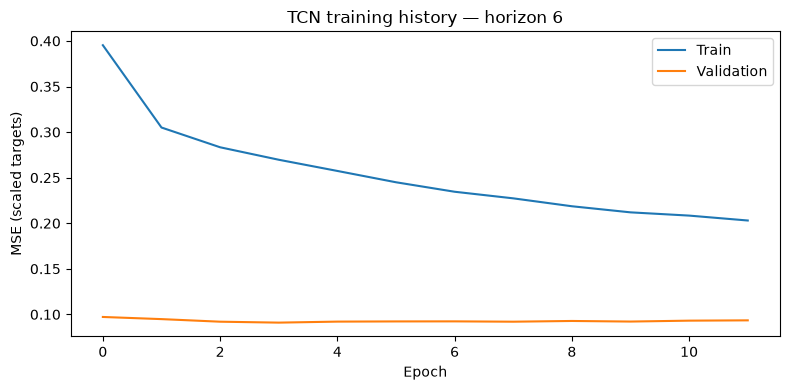

TCN H=6: best epoch 4; best val MSE=0.090980
TCN H=24: windows train/validation/test = 203,266/41,659/42,558; test count matches saved LSTM pooled metrics.
TCN H=24 | epoch 01/50 | train=0.52025 | val=0.13286 | lr=1.00e-03
TCN H=24 | epoch 02/50 | train=0.40091 | val=0.12540 | lr=1.00e-03
TCN H=24 | epoch 03/50 | train=0.35853 | val=0.12817 | lr=1.00e-03
TCN H=24 | epoch 04/50 | train=0.32832 | val=0.12850 | lr=1.00e-03
TCN H=24 | epoch 05/50 | train=0.31245 | val=0.12564 | lr=1.00e-03
TCN H=24 | epoch 06/50 | train=0.29460 | val=0.12713 | lr=5.00e-04
TCN H=24 | epoch 07/50 | train=0.27187 | val=0.12880 | lr=5.00e-04
TCN H=24 | epoch 08/50 | train=0.26432 | val=0.13382 | lr=5.00e-04
TCN H=24 | epoch 09/50 | train=0.25610 | val=0.13733 | lr=5.00e-04
TCN H=24 | epoch 10/50 | train=0.24868 | val=0.12487 | lr=5.00e-04
TCN H=24 | epoch 11/50 | train=0.24858 | val=0.13404 | lr=5.00e-04
TCN H=24 | epoch 12/50 | train=0.24005 | val=0.14681 | lr=5.00e-04
TCN H=24 | epoch 13/50 | train=0.23452 |

C:\Users\jains\AppData\Local\Temp\ipykernel_29412\3929085749.py:122: Pandas4Warning: The inplace keyword in DataFrame.sort_values is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  current.sort_values(["horizon", "target", "station"], inplace=True)


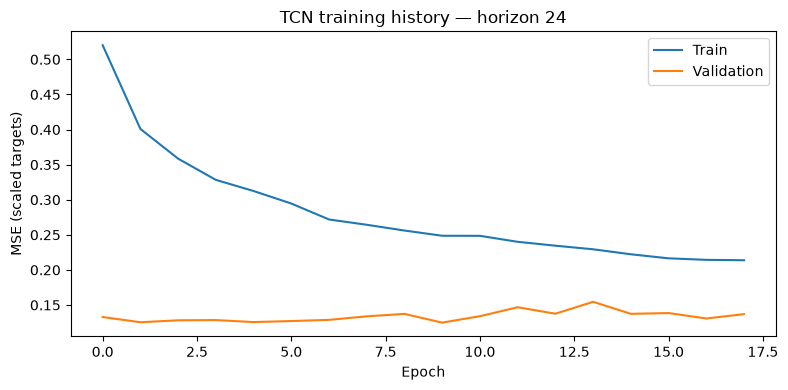

TCN H=24: best epoch 10; best val MSE=0.124872
1D-CNN H=1: windows train/validation/test = 203,749/42,142/43,041; test count matches saved LSTM pooled metrics.
1D-CNN H= 1 | epoch 01/50 | train=0.32032 | val=0.08761 | lr=1.00e-03
1D-CNN H= 1 | epoch 02/50 | train=0.17469 | val=0.08325 | lr=1.00e-03
1D-CNN H= 1 | epoch 03/50 | train=0.15376 | val=0.07455 | lr=1.00e-03
1D-CNN H= 1 | epoch 04/50 | train=0.14576 | val=0.08331 | lr=1.00e-03
1D-CNN H= 1 | epoch 05/50 | train=0.14176 | val=0.06684 | lr=1.00e-03
1D-CNN H= 1 | epoch 06/50 | train=0.13592 | val=0.06464 | lr=1.00e-03
1D-CNN H= 1 | epoch 07/50 | train=0.13358 | val=0.06357 | lr=1.00e-03
1D-CNN H= 1 | epoch 08/50 | train=0.13085 | val=0.06329 | lr=1.00e-03
1D-CNN H= 1 | epoch 09/50 | train=0.12858 | val=0.06139 | lr=1.00e-03
1D-CNN H= 1 | epoch 10/50 | train=0.12764 | val=0.06148 | lr=1.00e-03
1D-CNN H= 1 | epoch 11/50 | train=0.12559 | val=0.06287 | lr=1.00e-03
1D-CNN H= 1 | epoch 12/50 | train=0.12493 | val=0.06141 | lr=1.00e-03


C:\Users\jains\AppData\Local\Temp\ipykernel_29412\3929085749.py:122: Pandas4Warning: The inplace keyword in DataFrame.sort_values is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  current.sort_values(["horizon", "target", "station"], inplace=True)


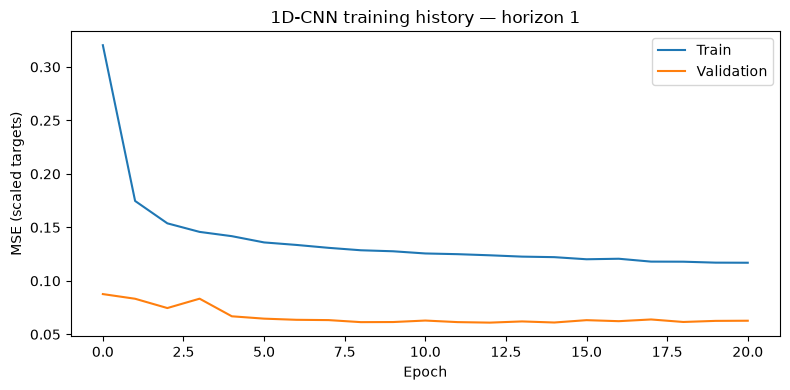

1D-CNN H=1: best epoch 13; best val MSE=0.060927
1D-CNN H=6: windows train/validation/test = 203,644/42,037/42,936; test count matches saved LSTM pooled metrics.
1D-CNN H= 6 | epoch 01/50 | train=0.46062 | val=0.12480 | lr=1.00e-03
1D-CNN H= 6 | epoch 02/50 | train=0.38675 | val=0.11754 | lr=1.00e-03
1D-CNN H= 6 | epoch 03/50 | train=0.36350 | val=0.11671 | lr=1.00e-03
1D-CNN H= 6 | epoch 04/50 | train=0.34990 | val=0.11230 | lr=1.00e-03
1D-CNN H= 6 | epoch 05/50 | train=0.34232 | val=0.11567 | lr=1.00e-03
1D-CNN H= 6 | epoch 06/50 | train=0.33346 | val=0.11532 | lr=1.00e-03
1D-CNN H= 6 | epoch 07/50 | train=0.32811 | val=0.11366 | lr=1.00e-03
1D-CNN H= 6 | epoch 08/50 | train=0.32221 | val=0.12366 | lr=5.00e-04
1D-CNN H= 6 | epoch 09/50 | train=0.31429 | val=0.11129 | lr=5.00e-04
1D-CNN H= 6 | epoch 10/50 | train=0.30970 | val=0.11130 | lr=5.00e-04
1D-CNN H= 6 | epoch 11/50 | train=0.30763 | val=0.11338 | lr=5.00e-04
1D-CNN H= 6 | epoch 12/50 | train=0.30474 | val=0.11375 | lr=5.00e-0

C:\Users\jains\AppData\Local\Temp\ipykernel_29412\3929085749.py:122: Pandas4Warning: The inplace keyword in DataFrame.sort_values is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  current.sort_values(["horizon", "target", "station"], inplace=True)


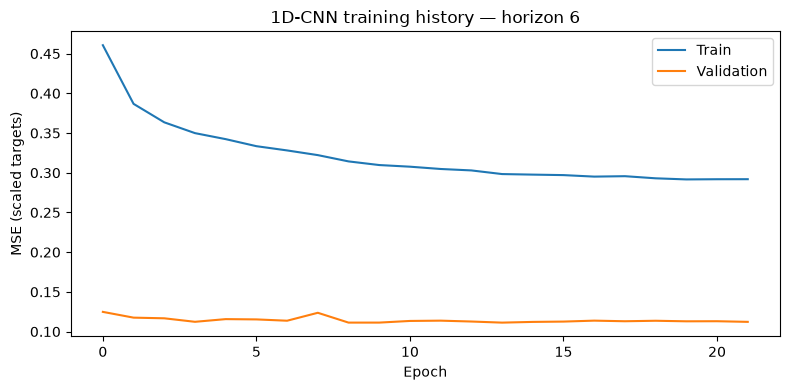

1D-CNN H=6: best epoch 14; best val MSE=0.111265
1D-CNN H=24: windows train/validation/test = 203,266/41,659/42,558; test count matches saved LSTM pooled metrics.
1D-CNN H=24 | epoch 01/50 | train=0.54161 | val=0.17565 | lr=1.00e-03
1D-CNN H=24 | epoch 02/50 | train=0.46857 | val=0.15788 | lr=1.00e-03
1D-CNN H=24 | epoch 03/50 | train=0.44152 | val=0.15400 | lr=1.00e-03
1D-CNN H=24 | epoch 04/50 | train=0.42239 | val=0.20290 | lr=1.00e-03
1D-CNN H=24 | epoch 05/50 | train=0.40692 | val=0.19295 | lr=1.00e-03
1D-CNN H=24 | epoch 06/50 | train=0.39768 | val=0.18677 | lr=1.00e-03
1D-CNN H=24 | epoch 07/50 | train=0.38747 | val=0.18267 | lr=5.00e-04
1D-CNN H=24 | epoch 08/50 | train=0.37681 | val=0.14828 | lr=5.00e-04
1D-CNN H=24 | epoch 09/50 | train=0.36929 | val=0.20330 | lr=5.00e-04
1D-CNN H=24 | epoch 10/50 | train=0.36641 | val=0.18022 | lr=5.00e-04
1D-CNN H=24 | epoch 11/50 | train=0.36381 | val=0.16982 | lr=5.00e-04
1D-CNN H=24 | epoch 12/50 | train=0.36038 | val=0.20179 | lr=2.50e-

C:\Users\jains\AppData\Local\Temp\ipykernel_29412\3929085749.py:122: Pandas4Warning: The inplace keyword in DataFrame.sort_values is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  current.sort_values(["horizon", "target", "station"], inplace=True)


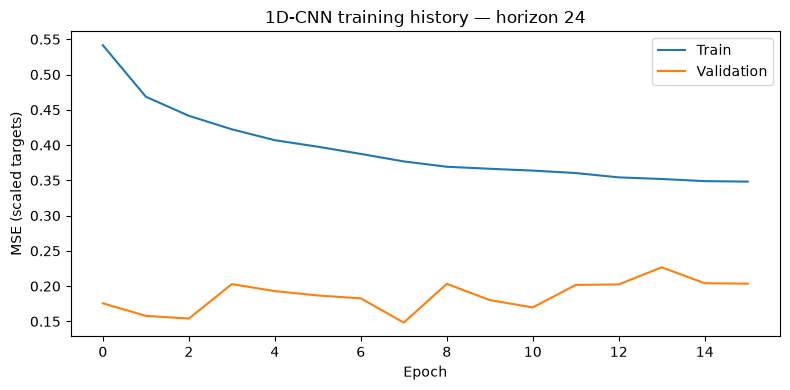

1D-CNN H=24: best epoch 8; best val MSE=0.148277
Saved pooled and per-station TCN metrics: 132 rows
Saved pooled and per-station 1D-CNN metrics: 132 rows
Training time reflects this execution/resume only; prior interrupted time was not recorded.


,model,horizon,best_epoch,best_train_loss,best_validation_loss,epochs_run,training_seconds_model_total
0,TCN,1,13,0.093460,0.054750,21,6223.028324
1,TCN,6,4,0.269660,0.090980,12,6223.028324
2,TCN,24,10,0.248678,0.124872,18,6223.028324
3,1D-CNN,1,13,0.123882,0.060927,21,3578.313163
4,1D-CNN,6,14,0.298346,0.111265,22,3578.313163
5,1D-CNN,24,8,0.376813,0.148277,16,3578.313163


In [8]:
import copy
import json
import os
import re
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def regression_metrics(actual, predicted):
    actual, predicted = np.asarray(actual, dtype=float), np.asarray(predicted, dtype=float)
    valid = np.isfinite(actual) & np.isfinite(predicted)
    actual, predicted = actual[valid], predicted[valid]
    if not len(actual):
        return {"MAE": np.nan, "RMSE": np.nan, "R2": np.nan, "n": 0}
    return {
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "R2": r2_score(actual, predicted) if len(actual) >= 2 else np.nan,
        "n": len(actual),
    }

lstm_reference_path = LSTM_RESULTS_DIR / "lstm_all_horizons_metrics.csv"
if not lstm_reference_path.is_file():
    raise FileNotFoundError(f"Saved pooled LSTM metrics not found: {lstm_reference_path}")
lstm_reference = pd.read_csv(lstm_reference_path)
required_cols = {"horizon", "target", "station", "method", "MAE", "RMSE", "R2", "n"}
if not required_cols.issubset(lstm_reference.columns):
    raise ValueError(f"Unexpected LSTM metrics columns: {lstm_reference.columns.tolist()}")

# Recovery metadata for the run that was stopped before resumable checkpoints existed.
LEGACY_PROGRESS = {
    ("TCN", 1): {
        "last_epoch": 21, "best_epoch": 13, "best_train_loss": 0.09346,
        "best_validation_loss": 0.054754, "epochs_run": 21,
    },
    ("TCN", 6): {
        "last_epoch": 9,
        "train_loss": [0.39531, 0.30501, 0.28334, 0.26966],
        "validation_loss": [0.09719, 0.09483, 0.09200, 0.09098],
    },
}

def read_previous_epoch_logs():
    logs = {}
    notebook_path = Path.cwd() / "03_TCN_CNN_Comparison.ipynb"
    if not notebook_path.is_file():
        return logs
    notebook_data = json.loads(notebook_path.read_text(encoding="utf-8"))
    old_training_cell = next(
        (cell for cell in notebook_data.get("cells", []) if cell.get("id") == "comparison-training"),
        None,
    )
    if old_training_cell is None:
        return logs
    text_parts = []
    for output in old_training_cell.get("outputs", []):
        if output.get("output_type") == "stream":
            text = output.get("text", "")
            text_parts.append("".join(text) if isinstance(text, list) else str(text))
    pattern = re.compile(
        r"(?P<model>TCN|1D-CNN) H=\s*(?P<horizon>\d+)\s*\|\s*epoch\s*"
        r"(?P<epoch>\d+)/\d+\s*\|\s*train=(?P<train>[0-9.eE+-]+)\s*\|\s*"
        r"val=(?P<val>[0-9.eE+-]+)\s*\|\s*lr=(?P<lr>[0-9.eE+-]+)"
    )
    for line in "".join(text_parts).splitlines():
        match = pattern.search(line)
        if match is None:
            continue
        key = (match.group("model"), int(match.group("horizon")))
        entry = logs.setdefault(
            key, {"epoch_numbers": [], "train_loss": [], "validation_loss": [], "learning_rates": []}
        )
        entry["epoch_numbers"].append(int(match.group("epoch")))
        entry["train_loss"].append(float(match.group("train")))
        entry["validation_loss"].append(float(match.group("val")))
        entry["learning_rates"].append(float(match.group("lr")))
    for key, entry in logs.items():
        best_idx = int(np.argmin(entry["validation_loss"]))
        entry["last_epoch"] = max(entry["epoch_numbers"])
        entry["best_epoch"] = entry["epoch_numbers"][best_idx]
        entry["best_train_loss"] = entry["train_loss"][best_idx]
        entry["best_validation_loss"] = entry["validation_loss"][best_idx]
        entry["epochs_run"] = len(entry["epoch_numbers"])
    for key, fallback in LEGACY_PROGRESS.items():
        logs.setdefault(key, fallback)
    return logs

previous_progress = read_previous_epoch_logs()
training_records = []
model_metrics = {"TCN": [], "1D-CNN": []}
model_predictions = {"TCN": {}, "1D-CNN": {}}

def add_prediction_metrics(model_name, horizon, prediction_frame):
    station_names = sorted(prediction_frame["station"].astype(str).unique())
    for target in TARGETS:
        actual = prediction_frame[f"{target}_actual"].to_numpy(dtype=float)
        predicted = prediction_frame[f"{target}_predicted"].to_numpy(dtype=float)
        groups = [("overall", np.ones(len(prediction_frame), dtype=bool))] + [
            (station, prediction_frame["station"].astype(str).eq(station).to_numpy())
            for station in station_names
        ]
        for group, mask in groups:
            model_metrics[model_name].append({
                "horizon": horizon, "target": target, "station": group,
                "method": model_name, **regression_metrics(actual[mask], predicted[mask]),
            })

def save_horizon_metrics(model_name, model_key, horizon):
    metrics_path = RESULTS_DIR / f"{model_key}_all_horizons_metrics.csv"
    current = pd.DataFrame([
        row for row in model_metrics[model_name] if row["horizon"] == horizon
    ])
    if metrics_path.is_file():
        saved = pd.read_csv(metrics_path)
        saved = saved.loc[
            ~saved["horizon"].eq(horizon) | ~saved["method"].eq(model_name)
        ]
        current = pd.concat([saved, current], ignore_index=True)
    current.sort_values(["horizon", "target", "station"], inplace=True)
    current.to_csv(metrics_path, index=False)

for model_name in ("TCN", "1D-CNN"):
    model_started = time.time()
    model_key = "tcn" if model_name == "TCN" else "1d_cnn"
    for horizon in HORIZONS:
        set_seed(RANDOM_SEED)
        datasets, station_scalers, stations = build_split_datasets(horizon)
        if any(len(datasets[name]) == 0 for name in ("train", "validation", "test")):
            raise ValueError(f"At least one split has no valid windows for horizon {horizon}.")
        window_counts = {name: len(ds) for name, ds in datasets.items()}
        reference_test_counts = lstm_reference.loc[
            lstm_reference["horizon"].eq(horizon)
            & lstm_reference["station"].eq("overall")
            & lstm_reference["method"].eq("LSTM"), "n"
        ]
        if len(reference_test_counts) != 2 or not (reference_test_counts.astype(int) == window_counts["test"]).all():
            raise ValueError(
                f"Test windows {window_counts['test']} do not match pooled LSTM counts "
                f"for H={horizon}: {reference_test_counts.tolist()}"
            )
        print(
            f"{model_name} H={horizon}: windows train/validation/test = "
            f"{window_counts['train']:,}/{window_counts['validation']:,}/{window_counts['test']:,}; "
            "test count matches saved LSTM pooled metrics."
        )

        weights_path = RESULTS_DIR / f"{model_key}_horizon_{horizon}_best.pt"
        resume_path = RESULTS_DIR / f"{model_key}_horizon_{horizon}_resume.pt"
        prediction_path = RESULTS_DIR / f"{model_key}_horizon_{horizon}_test_predictions.csv"
        loss_path = RESULTS_DIR / f"{model_key}_horizon_{horizon}_loss.png"
        progress = previous_progress.get((model_name, horizon))

        # Reuse completed horizons, including their previous prediction files, instead of retraining.
        if weights_path.is_file() and prediction_path.is_file() and loss_path.is_file() and progress:
            prediction_frame = pd.read_csv(prediction_path, parse_dates=["datetime"])
            if len(prediction_frame) != window_counts["test"]:
                raise ValueError(
                    f"Saved predictions contain {len(prediction_frame)} rows but H={horizon} "
                    f"requires {window_counts['test']}."
                )
            model_predictions[model_name][horizon] = prediction_frame
            add_prediction_metrics(model_name, horizon, prediction_frame)
            training_records.append({
                "model": model_name, "horizon": horizon,
                "best_epoch": progress["best_epoch"],
                "best_train_loss": progress["best_train_loss"],
                "best_validation_loss": progress["best_validation_loss"],
                "epochs_run": progress["epochs_run"],
                "training_seconds_model_total": np.nan,
            })
            save_horizon_metrics(model_name, model_key, horizon)
            print(f"Reusing completed {model_name} H={horizon} artifacts; no retraining.")
            continue

        train_loader_generator = torch.Generator().manual_seed(RANDOM_SEED)
        train_loader = DataLoader(
            datasets["train"], batch_size=BATCH_SIZE, shuffle=True, num_workers=0,
            pin_memory=DEVICE.type == "cuda", generator=train_loader_generator,
        )
        val_loader = DataLoader(
            datasets["validation"], batch_size=BATCH_SIZE, shuffle=False, num_workers=0,
            pin_memory=DEVICE.type == "cuda",
        )
        test_loader = DataLoader(
            datasets["test"], batch_size=BATCH_SIZE, shuffle=False, num_workers=0,
            pin_memory=DEVICE.type == "cuda",
        )
        model = (PooledTCN(len(FEATURES)) if model_name == "TCN" else PooledCNN1D(len(FEATURES))).to(DEVICE)
        optimizer = torch.optim.Adam(model.parameters(), lr=LR)
        criterion = nn.MSELoss()
        scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
            optimizer, mode="min", factor=0.5, patience=SCHEDULER_PATIENCE
        )
        best_val_loss, best_state, best_epoch = float("inf"), None, 0
        no_improvement = 0
        history = {"train_loss": [], "validation_loss": []}
        start_epoch = 1

        if resume_path.is_file():
            resume_state = torch.load(resume_path, map_location=DEVICE, weights_only=True)
            if resume_state.get("model_name") != model_name or int(resume_state.get("horizon", -1)) != horizon:
                raise ValueError(f"Resume checkpoint does not match {model_name} H={horizon}: {resume_path}")
            model.load_state_dict(resume_state["model_state"])
            optimizer.load_state_dict(resume_state["optimizer_state"])
            scheduler.load_state_dict(resume_state["scheduler_state"])
            history = resume_state["history"]
            best_val_loss = float(resume_state["best_val_loss"])
            best_state = resume_state["best_state"]
            best_epoch = int(resume_state["best_epoch"])
            no_improvement = int(resume_state["no_improvement"])
            start_epoch = int(resume_state["epoch"]) + 1
            train_loader_generator.set_state(resume_state["train_loader_generator_state"].cpu())
            torch.set_rng_state(resume_state["torch_rng_state"].cpu())
            if DEVICE.type == "cuda" and resume_state.get("cuda_rng_state") is not None:
                torch.cuda.set_rng_state_all(resume_state["cuda_rng_state"])
            print(
                f"Exact resume: {model_name} H={horizon} after epoch {start_epoch - 1}; "
                "optimizer, scheduler, history, and RNG state restored."
            )
        elif weights_path.is_file() and progress and progress.get("validation_loss"):
            # The interrupted legacy run saved only best weights, not optimizer moments.
            best_idx = int(np.argmin(progress["validation_loss"]))
            best_epoch = best_idx + 1
            history = {
                "train_loss": list(progress["train_loss"][:best_epoch]),
                "validation_loss": list(progress["validation_loss"][:best_epoch]),
            }
            best_val_loss = float(history["validation_loss"][-1])
            best_state = torch.load(weights_path, map_location=DEVICE, weights_only=True)
            model.load_state_dict(best_state)
            for previous_val in history["validation_loss"]:
                scheduler.step(previous_val)
            start_epoch = best_epoch + 1
            print(
                f"Warm-starting {model_name} H={horizon} from its best saved epoch {best_epoch} "
                f"(the old run reached epoch {progress.get('last_epoch', best_epoch)}). "
                "The old checkpoint has no Adam moments; this legacy continuation reinitializes Adam "
                "and repeats epochs after the best checkpoint. Future interruptions resume exactly "
                "from the per-epoch resume checkpoint."
            )

        for epoch in range(start_epoch, EPOCHS + 1):
            if no_improvement >= EARLY_STOPPING_PATIENCE:
                print("Early-stopping patience was already exhausted in the saved checkpoint.")
                break
            model.train()
            train_sum, train_count = 0.0, 0
            for x, y, _, _, _ in train_loader:
                x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
                optimizer.zero_grad(set_to_none=True)
                loss = criterion(model(x), y)
                loss.backward()
                optimizer.step()
                train_sum += loss.item() * len(x)
                train_count += len(x)
            train_loss = train_sum / train_count
            model.eval()
            val_sum, val_count = 0.0, 0
            with torch.no_grad():
                for x, y, _, _, _ in val_loader:
                    x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
                    val_sum += criterion(model(x), y).item() * len(x)
                    val_count += len(x)
            val_loss = val_sum / val_count
            scheduler.step(val_loss)
            history["train_loss"].append(train_loss)
            history["validation_loss"].append(val_loss)
            if val_loss < best_val_loss:
                best_val_loss, best_epoch = val_loss, epoch
                best_state = copy.deepcopy(model.state_dict())
                torch.save(best_state, weights_path)
                no_improvement = 0
            else:
                no_improvement += 1
            print(
                f"{model_name} H={horizon:>2} | epoch {epoch:02d}/{EPOCHS} | "
                f"train={train_loss:.5f} | val={val_loss:.5f} | "
                f"lr={optimizer.param_groups[0]['lr']:.2e}"
            )

            resume_state = {
                "model_name": model_name, "horizon": horizon, "epoch": epoch,
                "model_state": copy.deepcopy(model.state_dict()),
                "optimizer_state": optimizer.state_dict(),
                "scheduler_state": scheduler.state_dict(),
                "history": history, "best_val_loss": best_val_loss,
                "best_state": best_state, "best_epoch": best_epoch,
                "no_improvement": no_improvement,
                "train_loader_generator_state": train_loader_generator.get_state(),
                "torch_rng_state": torch.get_rng_state(),
                "cuda_rng_state": torch.cuda.get_rng_state_all() if DEVICE.type == "cuda" else None,
            }
            temporary_resume_path = resume_path.with_suffix(".pt.tmp")
            torch.save(resume_state, temporary_resume_path)
            os.replace(temporary_resume_path, resume_path)
            if no_improvement >= EARLY_STOPPING_PATIENCE:
                print(f"Early stopping after {EARLY_STOPPING_PATIENCE} epochs without validation improvement.")
                break

        if best_state is None:
            raise RuntimeError(f"No finite validation checkpoint: {model_name} H={horizon}")
        model.load_state_dict(best_state)
        model.eval()
        pred_scaled, actual, persistence, station_ids = [], [], [], []
        with torch.no_grad():
            for x, _, sid, y_original, persistence_original in test_loader:
                pred_scaled.append(model(x.to(DEVICE, non_blocking=True)).cpu().numpy())
                actual.append(y_original.numpy())
                persistence.append(persistence_original.numpy())
                station_ids.append(sid.numpy())
        pred_scaled = np.concatenate(pred_scaled)
        actual = np.concatenate(actual)
        persistence = np.concatenate(persistence)
        station_ids = np.concatenate(station_ids)
        station_names = np.asarray(stations, dtype=object)[station_ids]
        pred_original = np.empty_like(pred_scaled, dtype=np.float64)
        for station_idx, station in enumerate(stations):
            rows = station_ids == station_idx
            for target_idx, target in enumerate(TARGETS):
                pred_original[rows, target_idx] = station_scalers[station]["targets"][target].inverse_transform(
                    pred_scaled[rows, target_idx].reshape(-1, 1)
                ).ravel()

        test_dates = []
        # Dataset order is station-major, then chronological within each station.
        for station in stations:
            part = df.loc[
                df["station"].eq(station) & df["datetime"].between(TEST_START, TEST_END)
            ].reset_index(drop=True)
            first_target = LOOKBACK - 1 + horizon
            valid_positions = [
                pos for pos in range(first_target, len(part))
                if np.isfinite(part.loc[pos, TARGETS].to_numpy(dtype=float)).all()
            ]
            test_dates.extend(part.loc[valid_positions, "datetime"].tolist())
        prediction_frame = pd.DataFrame({
            "station": station_names, "datetime": test_dates,
            "PM10_actual": actual[:, 0], "PM10_predicted": pred_original[:, 0],
            "PM2.5_actual": actual[:, 1], "PM2.5_predicted": pred_original[:, 1],
        })
        model_predictions[model_name][horizon] = prediction_frame
        prediction_frame.to_csv(prediction_path, index=False)
        add_prediction_metrics(model_name, horizon, prediction_frame)
        save_horizon_metrics(model_name, model_key, horizon)

        fig, ax = plt.subplots(figsize=(8, 4))
        ax.plot(history["train_loss"], label="Train")
        ax.plot(history["validation_loss"], label="Validation")
        ax.set(
            title=f"{model_name} training history — horizon {horizon}",
            xlabel="Epoch", ylabel="MSE (scaled targets)",
        )
        ax.legend()
        fig.tight_layout()
        fig.savefig(loss_path, dpi=150)
        plt.show()
        training_records.append({
            "model": model_name, "horizon": horizon, "best_epoch": best_epoch,
            "best_train_loss": history["train_loss"][best_epoch - 1],
            "best_validation_loss": best_val_loss, "epochs_run": len(history["train_loss"]),
            "training_seconds_model_total": np.nan,
        })
        print(f"{model_name} H={horizon}: best epoch {best_epoch}; best val MSE={best_val_loss:.6f}")
    elapsed = time.time() - model_started
    for record in training_records:
        if record["model"] == model_name:
            record["training_seconds_model_total"] = elapsed

for name, rows in model_metrics.items():
    key = "tcn" if name == "TCN" else "1d_cnn"
    metrics_frame = pd.DataFrame(rows)
    metrics_frame.to_csv(RESULTS_DIR / f"{key}_all_horizons_metrics.csv", index=False)
    print(f"Saved pooled and per-station {name} metrics: {len(metrics_frame):,} rows")
training_summary = pd.DataFrame(training_records)
print("Training time reflects this execution/resume only; prior interrupted time was not recorded.")
display(training_summary)


## 7. Pooled comparison, per-station analysis, and plots

Saved comparison table: E:\coding\DL2project\tcn_cnn_results\model_comparison_results.csv


,target,horizon,Persistence_MAE,LSTM_MAE,TCN_MAE,1D-CNN_MAE,Persistence_RMSE,LSTM_RMSE,TCN_RMSE,1D-CNN_RMSE,Persistence_R2,LSTM_R2,TCN_R2,1D-CNN_R2
0,PM10,1,2.884,2.758,2.763,3.448,5.398,4.892,4.886,5.238,0.801,0.837,0.837,0.813
1,PM10,6,7.313,6.154,5.555,7.573,11.435,9.003,8.124,10.161,0.105,0.447,0.550,0.296
2,PM10,24,7.257,7.676,7.592,10.319,10.865,10.511,10.941,13.225,0.191,0.249,0.186,-0.189
3,PM2.5,1,2.056,1.975,2.002,2.408,4.037,3.676,3.699,3.881,0.857,0.882,0.880,0.868
4,PM2.5,6,5.627,4.580,4.202,5.758,9.369,7.180,6.439,8.091,0.230,0.550,0.638,0.428
5,PM2.5,24,5.545,5.728,5.938,8.139,8.706,8.440,9.065,10.911,0.334,0.380,0.285,-0.036


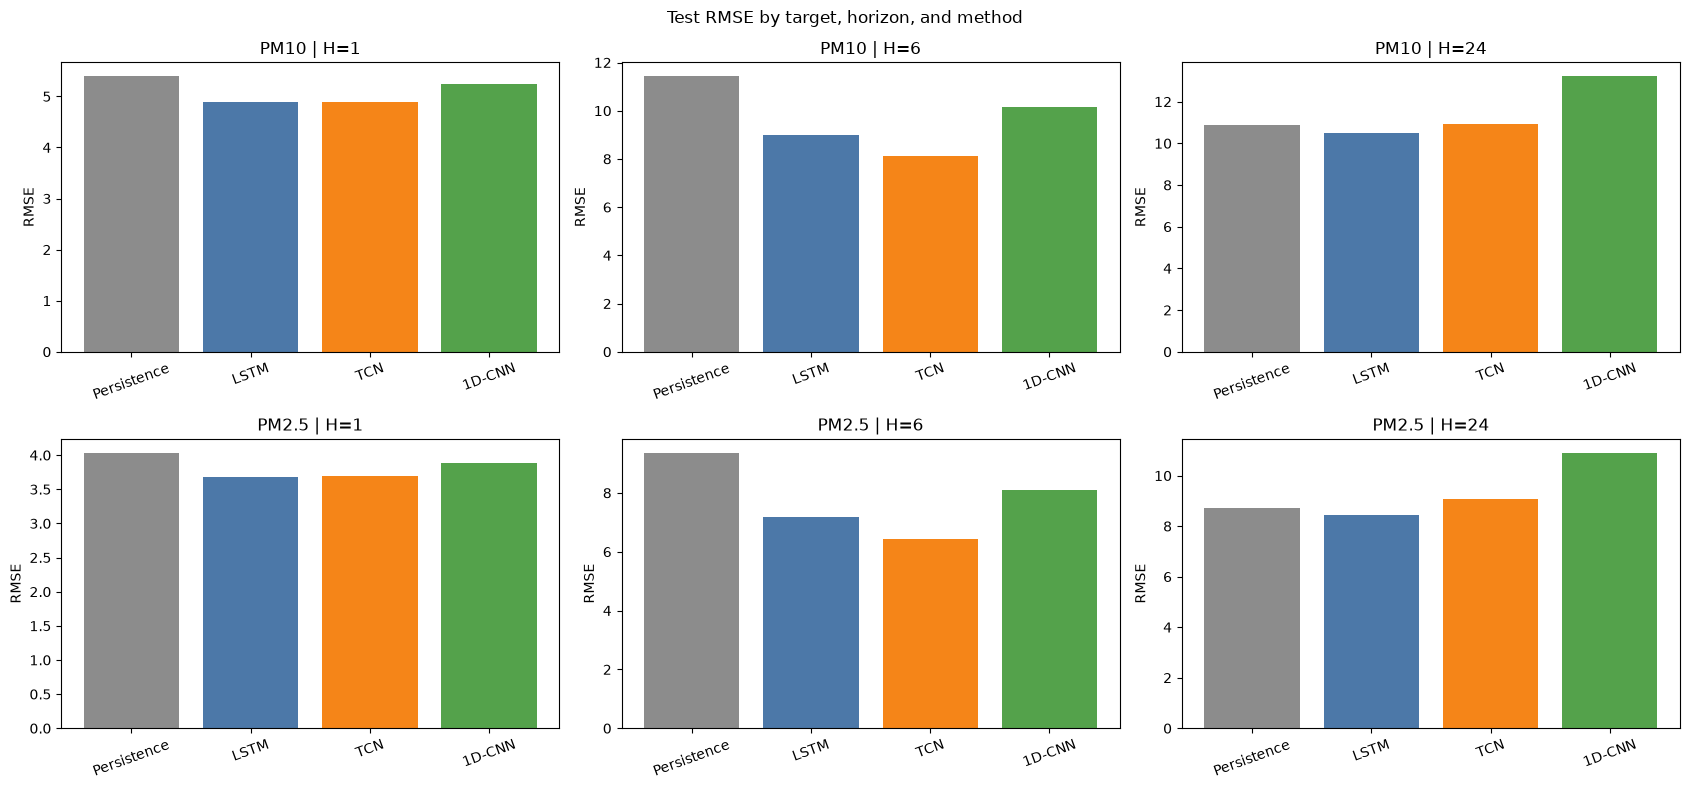

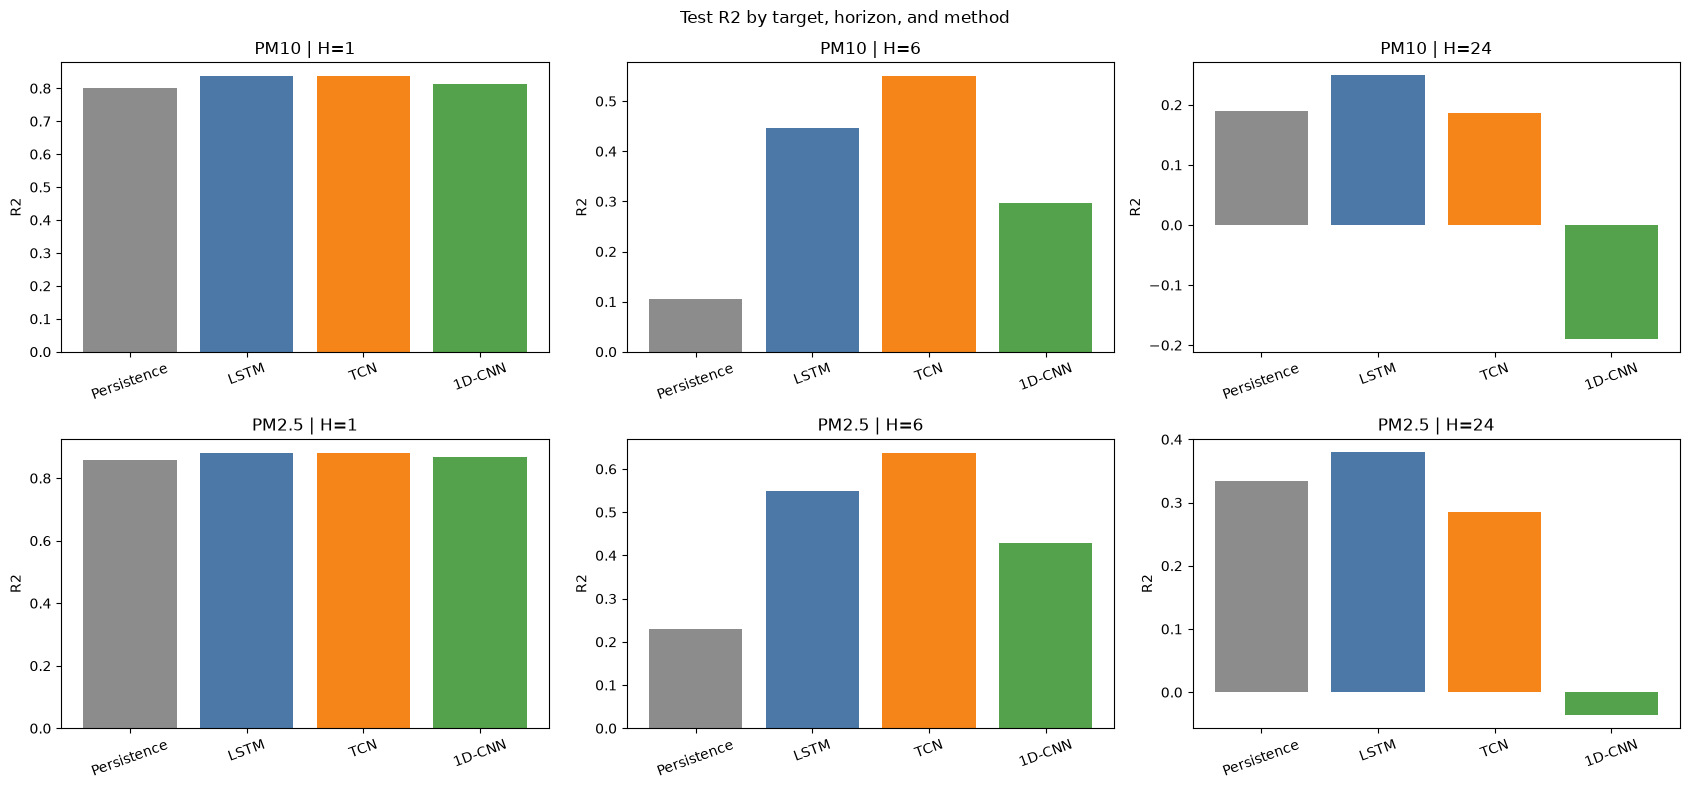

C:\Users\jains\AppData\Local\Temp\ipykernel_29412\46234837.py:68: UserWarning: Attempting to set identical low and high ylims makes transformation singular; automatically expanding.
  image = ax.imshow(station_rmse.to_numpy(), aspect="auto", cmap="magma")


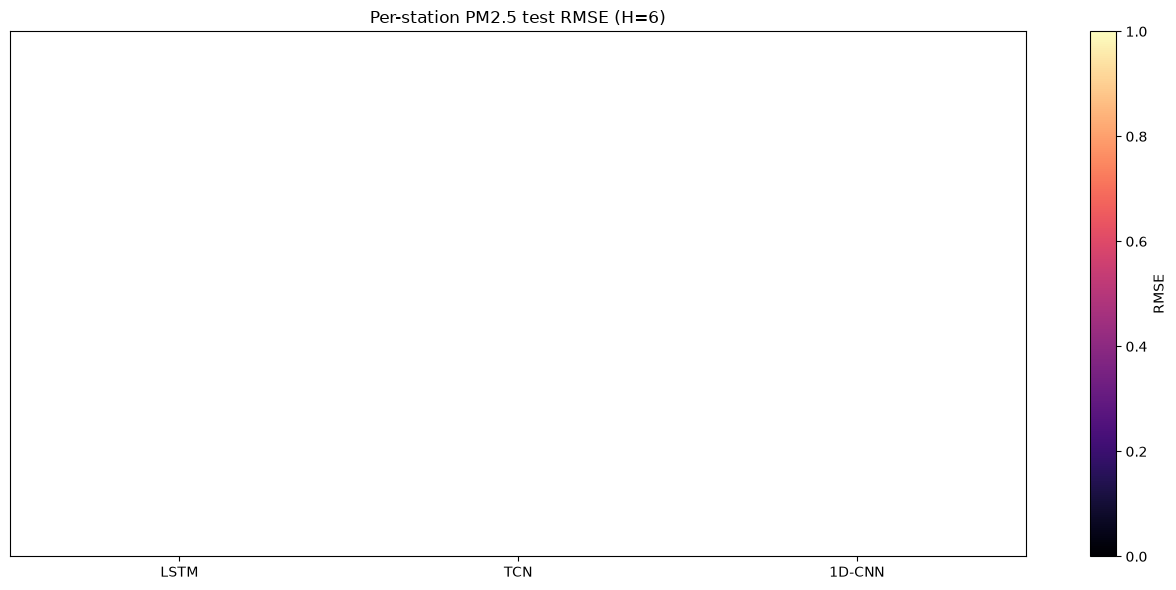

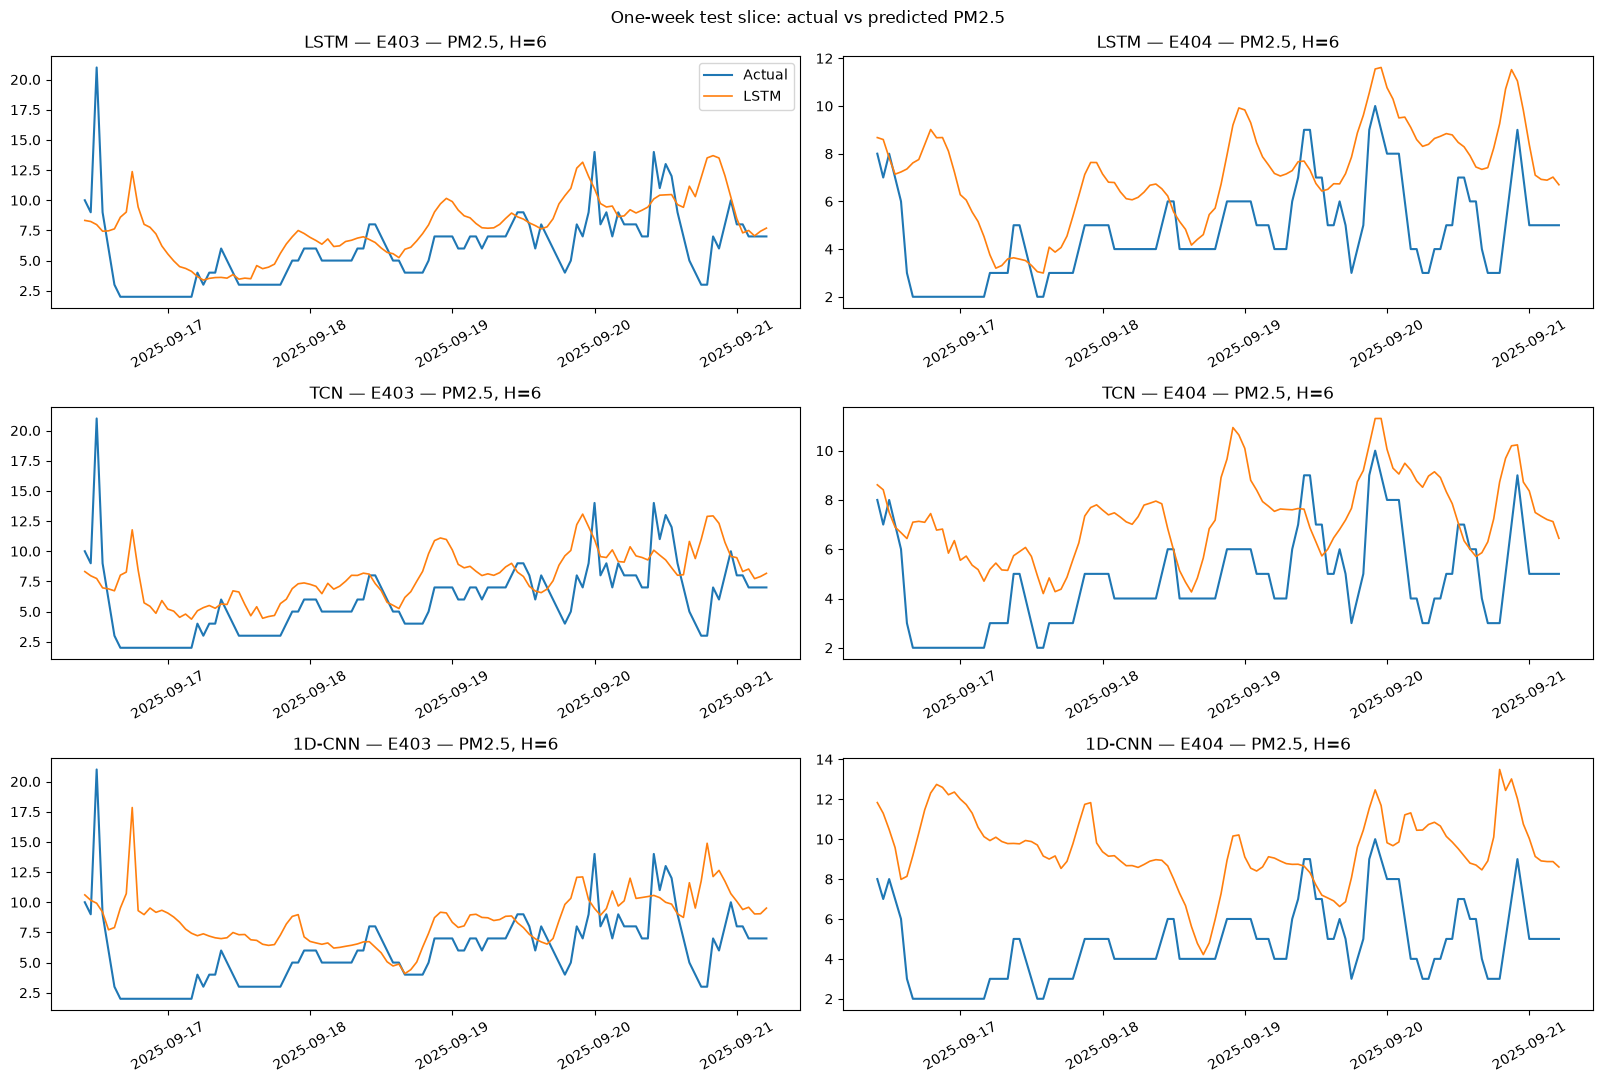

Training time covers this execution/resume only; prior interrupted time was not recorded.


,model,trainable_parameters,training_time_seconds
0,TCN,115778,6223.028324
1,1D-CNN,20194,3578.313163
2,LSTM (reference),53378,NaN


### Summary\n\n- **PM10, H=1:** TCN has the lowest RMSE (4.886), 9.5% lower than persistence.\n- **PM10, H=6:** TCN has the lowest RMSE (8.124), 29.0% lower than persistence.\n- **PM10, H=24:** LSTM has the lowest RMSE (10.511), 3.3% lower than persistence.\n- **PM2.5, H=1:** LSTM has the lowest RMSE (3.676), 8.9% lower than persistence.\n- **PM2.5, H=6:** TCN has the lowest RMSE (6.439), 31.3% lower than persistence.\n- **PM2.5, H=24:** LSTM has the lowest RMSE (8.440), 3.1% lower than persistence.\n\nOverfitting signals (scaled-target loss):\n- TCN H=1: best epoch 13/21; loss gap -0.0387 (ratio 0.59) — no strong early-stop / train-validation-gap signal.\n- TCN H=6: best epoch 4/12; loss gap -0.1787 (ratio 0.34) — early best epoch.\n- TCN H=24: best epoch 10/18; loss gap -0.1238 (ratio 0.50) — no strong early-stop / train-validation-gap signal.\n- 1D-CNN H=1: best epoch 13/21; loss gap -0.0630 (ratio 0.49) — no strong early-stop / train-validation-gap signal.\n- 1D-CNN H=6: best epoch 14/22; loss gap -0.1871 (ratio 0.37) — no strong early-stop / train-validation-gap signal.\n- 1D-CNN H=24: best epoch 8/16; loss gap -0.2285 (ratio 0.39) — no strong early-stop / train-validation-gap signal.

Outputs saved under E:\coding\DL2project\tcn_cnn_results


In [9]:

# LSTM file contains both the pooled LSTM and persistence rows.
lstm_pooled = lstm_reference.loc[lstm_reference["station"].eq("overall")].copy()
learned = pd.concat(
    [pd.DataFrame(model_metrics["TCN"]), pd.DataFrame(model_metrics["1D-CNN"])],
    ignore_index=True,
)
learned = learned.loc[learned["station"].eq("overall")]
comparison_long = pd.concat([lstm_pooled, learned], ignore_index=True)
method_order = ["Persistence", "LSTM", "TCN", "1D-CNN"]
metric_order = ["MAE", "RMSE", "R2"]
comparison_long = comparison_long.loc[comparison_long["method"].isin(method_order)]
wide = comparison_long.pivot_table(
    index=["target", "horizon"], columns="method",
    values=metric_order, aggfunc="first",
)
wide = wide.reindex(columns=pd.MultiIndex.from_product([metric_order, method_order]))
wide.columns = [f"{method}_{metric}" for metric, method in wide.columns]
comparison_wide = wide.reset_index().sort_values(["target", "horizon"]).reset_index(drop=True)
comparison_wide.to_csv(RESULTS_DIR / "model_comparison_results.csv", index=False)
print(f"Saved comparison table: {(RESULTS_DIR / 'model_comparison_results.csv').resolve()}")

def highlight_best(row):
    styles = [""] * len(row)
    positions = {name: idx for idx, name in enumerate(row.index)}
    for metric in metric_order:
        columns = [f"{method}_{metric}" for method in method_order]
        values = pd.to_numeric(row[columns], errors="coerce")
        best = values.max() if metric == "R2" else values.min()
        for column in columns:
            value = pd.to_numeric(pd.Series([row[column]]), errors="coerce").iloc[0]
            if pd.notna(value) and np.isclose(value, best):
                styles[positions[column]] = "background-color: #b7e4c7; font-weight: bold"
    return styles

display(comparison_wide.style.apply(highlight_best, axis=1).format(precision=3))

for metric in ("RMSE", "R2"):
    fig, axes = plt.subplots(2, 3, figsize=(17, 8), squeeze=False)
    for row_idx, target in enumerate(TARGETS):
        for col_idx, horizon in enumerate(HORIZONS):
            ax = axes[row_idx, col_idx]
            selected = comparison_wide.loc[
                comparison_wide["target"].eq(target) & comparison_wide["horizon"].eq(horizon)
            ]
            if selected.empty:
                raise ValueError(f"Missing comparison row for {target}, H={horizon}")
            vals = [selected[f"{method}_{metric}"].iloc[0] for method in method_order]
            ax.bar(method_order, vals, color=["#8c8c8c", "#4c78a8", "#f58518", "#54a24b"])
            ax.set_title(f"{target} | H={horizon}")
            ax.set_ylabel(metric)
            ax.tick_params(axis="x", rotation=20)
    fig.suptitle(f"Test {metric} by target, horizon, and method")
    fig.tight_layout()
    fig.savefig(RESULTS_DIR / f"comparison_{metric.lower()}_bars.png", dpi=160)
    plt.show()

per_station = comparison_long.loc[
    comparison_long["horizon"].eq(6) & comparison_long["target"].eq("PM2.5")
    & comparison_long["station"].ne("overall")
    & comparison_long["method"].isin(["LSTM", "TCN", "1D-CNN"]),
    ["station", "method", "RMSE"],
]
station_rmse = per_station.pivot(index="station", columns="method", values="RMSE")
station_rmse = station_rmse.reindex(columns=["LSTM", "TCN", "1D-CNN"])
if station_rmse.isna().any().any():
    raise ValueError("Per-station PM2.5 RMSE comparison is incomplete at H=6")
fig, ax = plt.subplots(figsize=(13, 6))
image = ax.imshow(station_rmse.to_numpy(), aspect="auto", cmap="magma")
ax.set_xticks(range(len(station_rmse.columns)), labels=station_rmse.columns)
ax.set_yticks(range(len(station_rmse.index)), labels=station_rmse.index)
ax.set_title("Per-station PM2.5 test RMSE (H=6)")
fig.colorbar(image, ax=ax, label="RMSE")
fig.tight_layout()
fig.savefig(RESULTS_DIR / "pm25_h6_per_station_rmse_heatmap.png", dpi=160)
plt.show()

# One-week H=6 test slice for PM2.5 at the first two stations, for all models.
lstm_path = LSTM_RESULTS_DIR / "lstm_horizon_6_test_predictions.csv"
if not lstm_path.is_file():
    raise FileNotFoundError(f"Saved LSTM test predictions not found: {lstm_path}")
lstm_predictions = pd.read_csv(lstm_path, parse_dates=["datetime"])
plot_stations = stations[:2]
plot_start, plot_end = TEST_START, min(TEST_END, TEST_START + pd.Timedelta(days=7))
fig, axes = plt.subplots(3, len(plot_stations), figsize=(16, 11), squeeze=False)
frames = [
    ("LSTM", lstm_predictions),
    ("TCN", model_predictions["TCN"][6]),
    ("1D-CNN", model_predictions["1D-CNN"][6]),
]
for row_idx, (model_name, frame) in enumerate(frames):
    frame = frame.copy()
    frame["datetime"] = pd.to_datetime(frame["datetime"])
    for col_idx, station in enumerate(plot_stations):
        plotted = frame.loc[
            frame["station"].eq(station) & frame["datetime"].between(plot_start, plot_end)
        ].sort_values("datetime")
        if plotted.empty:
            raise ValueError(f"No H=6 predictions for station {station}, model {model_name}")
        ax = axes[row_idx, col_idx]
        ax.plot(plotted["datetime"], plotted["PM2.5_actual"], label="Actual", linewidth=1.5)
        ax.plot(plotted["datetime"], plotted["PM2.5_predicted"], label=model_name, linewidth=1.2)
        ax.set_title(f"{model_name} — {station} — PM2.5, H=6")
        ax.tick_params(axis="x", rotation=30)
        if row_idx == 0 and col_idx == 0:
            ax.legend()
fig.suptitle("One-week test slice: actual vs predicted PM2.5")
fig.tight_layout()
fig.savefig(RESULTS_DIR / "h6_one_week_actual_vs_predicted.png", dpi=160)
plt.show()

time_rows = []
for name in ("TCN", "1D-CNN"):
    seconds = float(training_summary.loc[
        training_summary["model"].eq(name), "training_seconds_model_total"
    ].iloc[0])
    time_rows.append({
        "model": name, "trainable_parameters": PARAM_COUNTS[name],
        "training_time_seconds": seconds,
    })
time_rows.append({
    "model": "LSTM (reference)", "trainable_parameters": PARAM_COUNTS["LSTM"],
    "training_time_seconds": np.nan,
})
time_table = pd.DataFrame(time_rows)
print("Training time covers this execution/resume only; prior interrupted time was not recorded.")
display(time_table)
time_table.to_csv(RESULTS_DIR / "training_time_parameter_counts.csv", index=False)

lines = ["### Summary", ""]
for target in TARGETS:
    for horizon in HORIZONS:
        row = comparison_wide.loc[
            comparison_wide["target"].eq(target) & comparison_wide["horizon"].eq(horizon)
        ].iloc[0]
        rmse = {method: row[f"{method}_RMSE"] for method in method_order}
        winner = min(rmse, key=rmse.get)
        improvement = 100 * (row["Persistence_RMSE"] - rmse[winner]) / row["Persistence_RMSE"]
        lines.append(
            f"- **{target}, H={horizon}:** {winner} has the lowest RMSE ({rmse[winner]:.3f}), "
            f"{improvement:.1f}% lower than persistence."
        )
lines.extend(["", "Overfitting signals (scaled-target loss):"])
for _, record in training_summary.iterrows():
    gap = record["best_validation_loss"] - record["best_train_loss"]
    ratio = record["best_validation_loss"] / max(record["best_train_loss"], 1e-12)
    flags = []
    if record["best_epoch"] <= 5:
        flags.append("early best epoch")
    if ratio >= 1.5:
        flags.append("validation loss at least 1.5x train loss")
    signal = "; ".join(flags) if flags else "no strong early-stop / train-validation-gap signal"
    lines.append(
        f"- {record['model']} H={int(record['horizon'])}: best epoch "
        f"{int(record['best_epoch'])}/{int(record['epochs_run'])}; loss gap {gap:.4f} "
        f"(ratio {ratio:.2f}) — {signal}."
    )
display(Markdown("\\n".join(lines)))
print(f"Outputs saved under {RESULTS_DIR.resolve()}")
